In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [28]:
import os

print("Current Working Directory:", os.getcwd())
print("Files:", os.listdir("../data"))

Current Working Directory: c:\Users\LIKHITA\OneDrive\Documents\Desktop\Machine Learning\Week2_Day5\notebooks
Files: ['Telco-Customer-Churn.csv']


In [29]:
import os

print(os.listdir("../data"))

['Telco-Customer-Churn.csv']


In [30]:
# Inspect the first five lines of the CSV file

with open(data_path, "r", encoding="utf-8-sig") as file:
    for i in range(5):
        print(file.readline())

customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn

7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No

5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No

3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes

7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.3,1840.75,No



In [31]:
# Load the Telco Customer Churn dataset

data_path = "../data/Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

# Display first five records
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [32]:
# Import train-test split

from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns=["Churn", "customerID"])
y = df["Churn"]

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset shapes
print("Training Features Shape:", X_train.shape)
print("Testing Features Shape:", X_test.shape)

print("Training Target Shape:", y_train.shape)
print("Testing Target Shape:", y_test.shape)

Training Features Shape: (5634, 19)
Testing Features Shape: (1409, 19)
Training Target Shape: (5634,)
Testing Target Shape: (1409,)


In [33]:
# Create training dataset for EDA

train_df = X_train.copy()

# Add target column
train_df["Churn"] = y_train

# Check training dataset shape
print("Training Dataset Shape:", train_df.shape)

# Check column information
print("\nDataset Information:")
train_df.info()

Training Dataset Shape: (5634, 20)

Dataset Information:
<class 'pandas.DataFrame'>
Index: 5634 entries, 3738 to 5639
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   str    
 1   SeniorCitizen     5634 non-null   int64  
 2   Partner           5634 non-null   str    
 3   Dependents        5634 non-null   str    
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   str    
 6   MultipleLines     5634 non-null   str    
 7   InternetService   5634 non-null   str    
 8   OnlineSecurity    5634 non-null   str    
 9   OnlineBackup      5634 non-null   str    
 10  DeviceProtection  5634 non-null   str    
 11  TechSupport       5634 non-null   str    
 12  StreamingTV       5634 non-null   str    
 13  StreamingMovies   5634 non-null   str    
 14  Contract          5634 non-null   str    
 15  PaperlessBilling  5634 non-null   str    
 16

In [34]:
# Check missing values in each column

missing_values = train_df.isnull().sum()

print("Missing Values:")
print(missing_values)

print("\nTotal Missing Values:", missing_values.sum())

Missing Values:
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total Missing Values: 0


In [35]:
# Check duplicate records

duplicates = train_df.duplicated().sum()

print("Total Duplicate Records:", duplicates)

Total Duplicate Records: 15


In [36]:
# Check target class distribution

churn_counts = train_df["Churn"].value_counts()

print("Customer Churn Distribution:")
print(churn_counts)

print("\nChurn Percentage:")
print(train_df["Churn"].value_counts(normalize=True) * 100)

Customer Churn Distribution:
Churn
No     4139
Yes    1495
Name: count, dtype: int64

Churn Percentage:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64


In [87]:
# Split the dataset before performing EDA

from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["Churn"]
)

print("Training Data Shape:", train_df.shape)
print("Testing Data Shape:", test_df.shape)

# Use training data for EDA only

df = train_df.copy()

Training Data Shape: (5634, 21)
Testing Data Shape: (1409, 21)


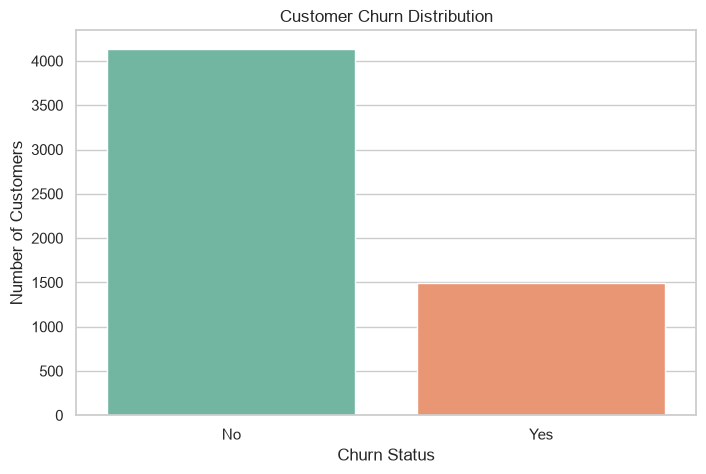

In [37]:
# Chart 1: Customer Churn Distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=train_df,
    x="Churn",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")

plt.savefig("../outputs/churn_distribution.png",
            dpi=300, bbox_inches="tight")

plt.show()

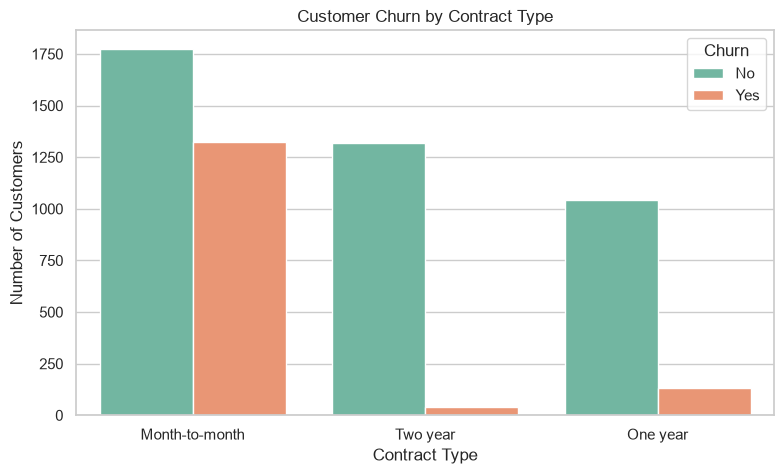

In [38]:
# Chart 2: Churn by Contract Type

plt.figure(figsize=(9, 5))

sns.countplot(
    data=train_df,
    x="Contract",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.legend(title="Churn")

plt.savefig("../outputs/churn_by_contract.png",
            dpi=300, bbox_inches="tight")

plt.show()

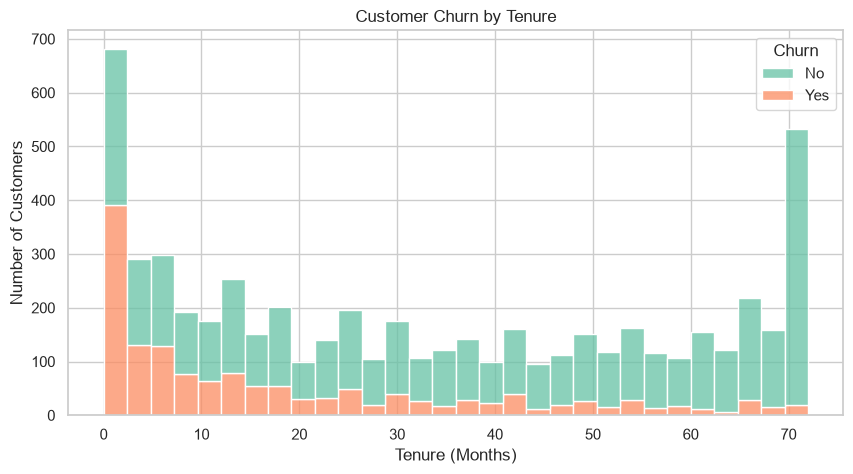

In [39]:
# Chart 3: Churn by Tenure

plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="tenure",
    hue="Churn",
    bins=30,
    multiple="stack",
    palette="Set2"
)

plt.title("Customer Churn by Tenure")
plt.xlabel("Tenure (Months)")
plt.ylabel("Number of Customers")

plt.savefig("../outputs/churn_by_tenure.png",
            dpi=300, bbox_inches="tight")

plt.show()

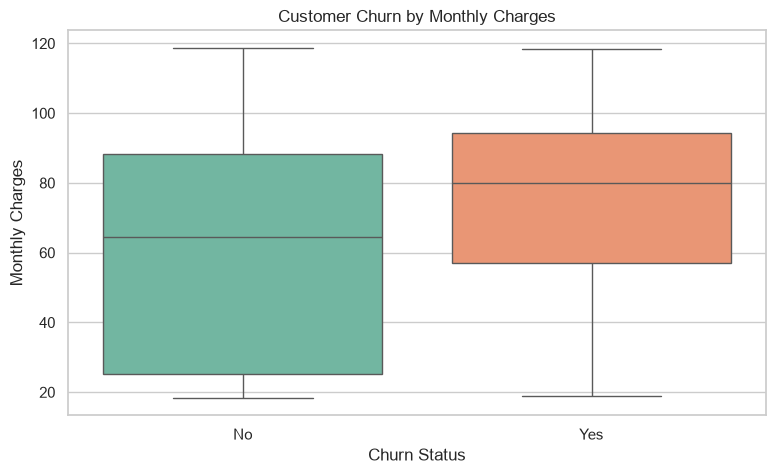

In [40]:
# Chart 4: Churn by Monthly Charges

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=train_df,
    x="Churn",
    y="MonthlyCharges",
    hue="Churn",
    palette="Set2",
    legend=False
)

plt.title("Customer Churn by Monthly Charges")
plt.xlabel("Churn Status")
plt.ylabel("Monthly Charges")

plt.savefig("../outputs/churn_by_monthly_charges.png",
            dpi=300, bbox_inches="tight")

plt.show()

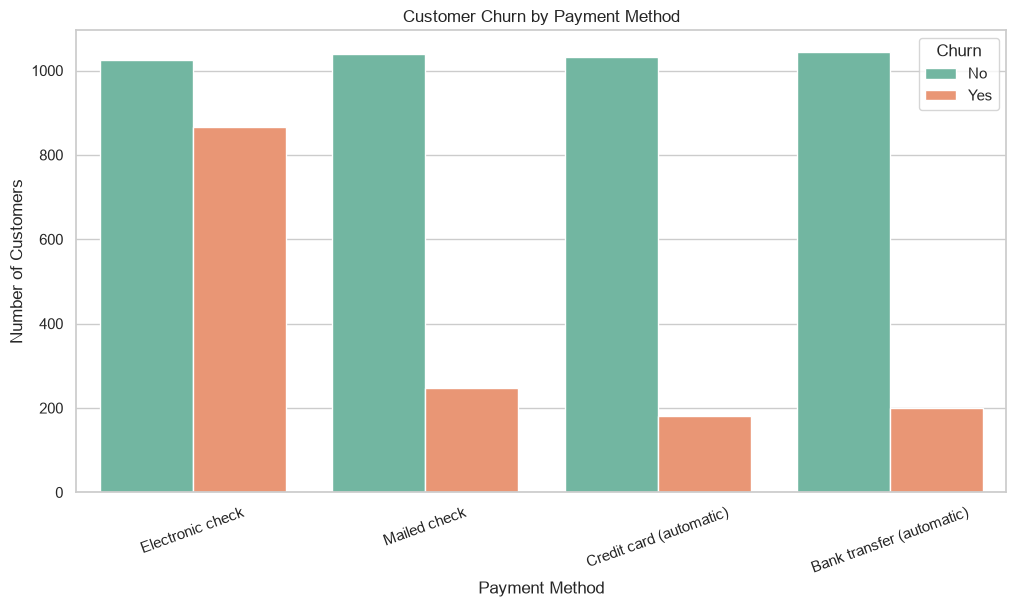

In [41]:
# Chart 5: Churn by Payment Method

plt.figure(figsize=(12, 6))

sns.countplot(
    data=train_df,
    x="PaymentMethod",
    hue="Churn",
    palette="Set2"
)

plt.title("Customer Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.legend(title="Churn")

plt.savefig("../outputs/churn_by_payment_method.png",
            dpi=300, bbox_inches="tight")

plt.show()

## Project Assumptions

1. The Telco Customer Churn dataset represents historical customer information.
2. The Churn column is the target variable.
3. CustomerID is excluded because it is an identifier and does not provide meaningful predictive information.
4. Customer service usage, contract type, tenure, and monthly charges may influence customer churn.
5. The dataset may contain class imbalance because fewer customers may leave than stay.
6. The training dataset will be used for exploratory data analysis and model development.
7. The test dataset will remain untouched until final model evaluation.
8. Missing values and inconsistent data types will be handled during preprocessing.

## Evaluation Metric Selection

**Selected Metric: F1-Score**

F1-score is selected because customer churn prediction may involve imbalanced classes.

Accuracy alone may not provide a complete picture of model performance.

F1-score balances Precision and Recall, helping the model identify customers who are likely to leave while reducing false predictions.

The goal is to build a model that effectively identifies potential customer churn.

## Exploratory Data Analysis – Key Observations

1. Customer Churn Distribution:
   The target distribution helps identify whether the dataset has class imbalance.

2. Churn by Contract Type:
   Contract type helps us understand differences in customer retention across subscription plans.

3. Churn by Tenure:
   Customer tenure helps identify how the duration of a customer relationship relates to churn.

4. Churn by Monthly Charges:
   Monthly charges help us investigate whether billing amounts are associated with customer churn.

5. Churn by Payment Method:
   Payment methods help us examine differences in churn patterns across payment preferences.

## Conclusion

Exploratory Data Analysis was performed using the training dataset.

Five visualizations were created to understand the relationship between customer churn and important features.

The test dataset was separated before EDA and kept untouched for final evaluation.

F1-score was selected as the primary evaluation metric.

In [42]:
# Load the dataset

data_path = "../data/Telco-Customer-Churn.csv"

df = pd.read_csv(data_path)

# Display first five rows
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [43]:
# Check dataset information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [44]:
# Check missing values in each column

df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [45]:
# Check duplicate rows

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [46]:
# Check customer churn distribution

df['Churn'].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

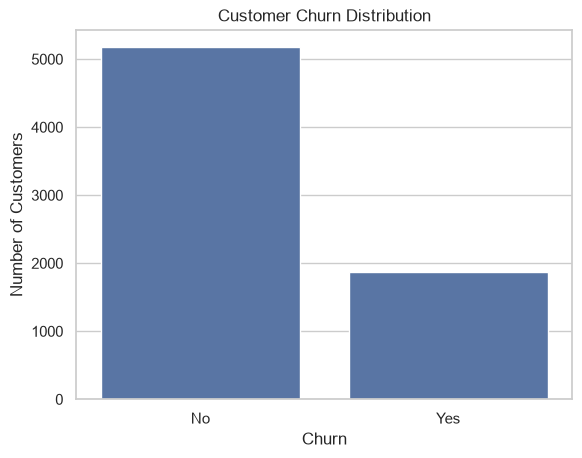

In [47]:
# Visualize customer churn distribution

import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(x='Churn', data=df)

plt.title('Customer Churn Distribution')
plt.xlabel('Churn')
plt.ylabel('Number of Customers')
plt.show()

In [48]:
# Calculate churn percentage

churn_percentage = df['Churn'].value_counts(normalize=True) * 100

print(churn_percentage)

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


gender
Male      3555
Female    3488
Name: count, dtype: int64


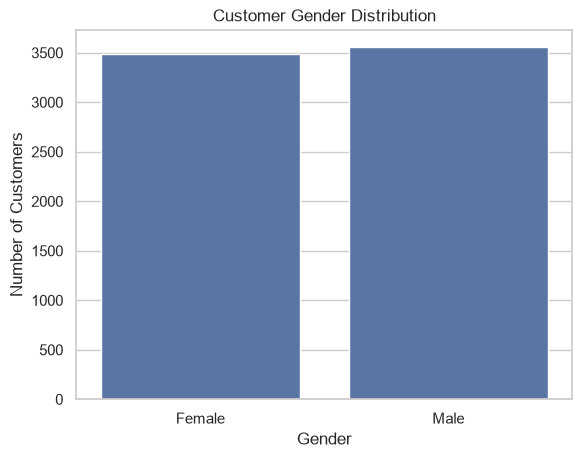

In [49]:
# Analyze gender distribution

print(df['gender'].value_counts())

sns.countplot(x='gender', data=df)

plt.title('Customer Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')
plt.show()

SeniorCitizen
0    5901
1    1142
Name: count, dtype: int64


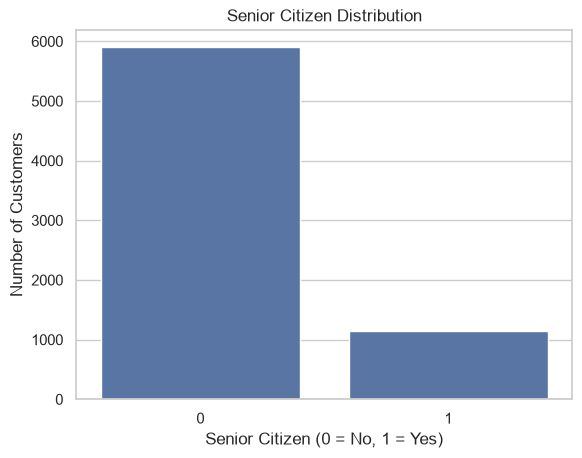

In [50]:
# Analyze senior citizen distribution

print(df['SeniorCitizen'].value_counts())

sns.countplot(x='SeniorCitizen', data=df)

plt.title('Senior Citizen Distribution')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')
plt.show()

count    7043.000000
mean       32.371149
std        24.559481
min         0.000000
25%         9.000000
50%        29.000000
75%        55.000000
max        72.000000
Name: tenure, dtype: float64


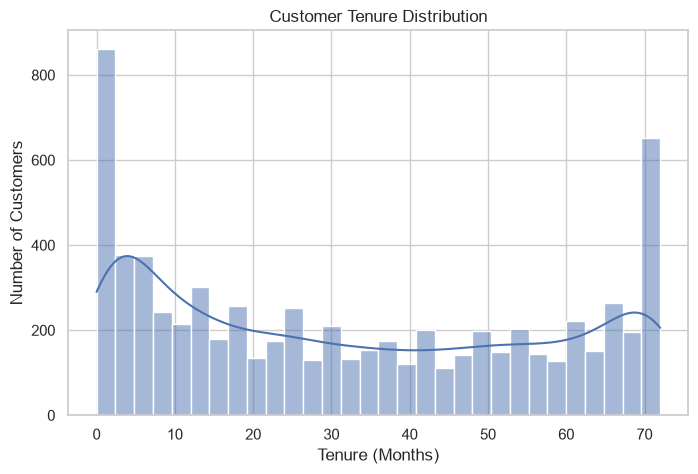

In [51]:
# Analyze customer tenure

print(df['tenure'].describe())

plt.figure(figsize=(8, 5))

sns.histplot(df['tenure'], bins=30, kde=True)

plt.title('Customer Tenure Distribution')
plt.xlabel('Tenure (Months)')
plt.ylabel('Number of Customers')

plt.show()

count    7043.000000
mean       64.761692
std        30.090047
min        18.250000
25%        35.500000
50%        70.350000
75%        89.850000
max       118.750000
Name: MonthlyCharges, dtype: float64


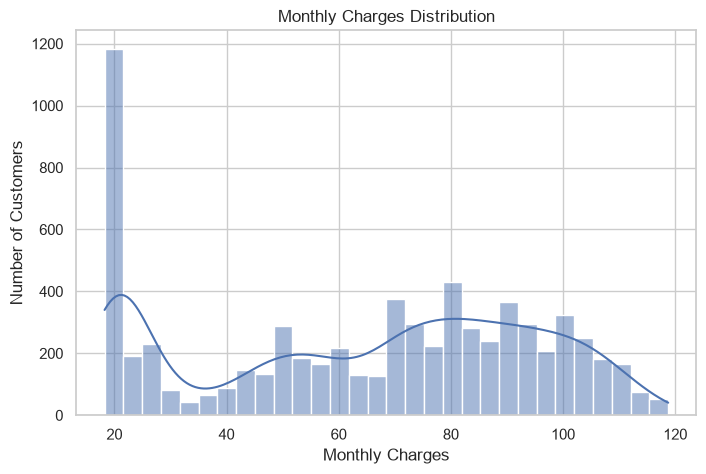

In [52]:
# Analyze monthly charges

print(df['MonthlyCharges'].describe())

plt.figure(figsize=(8, 5))

sns.histplot(df['MonthlyCharges'], bins=30, kde=True)

plt.title('Monthly Charges Distribution')
plt.xlabel('Monthly Charges')
plt.ylabel('Number of Customers')

plt.show()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64


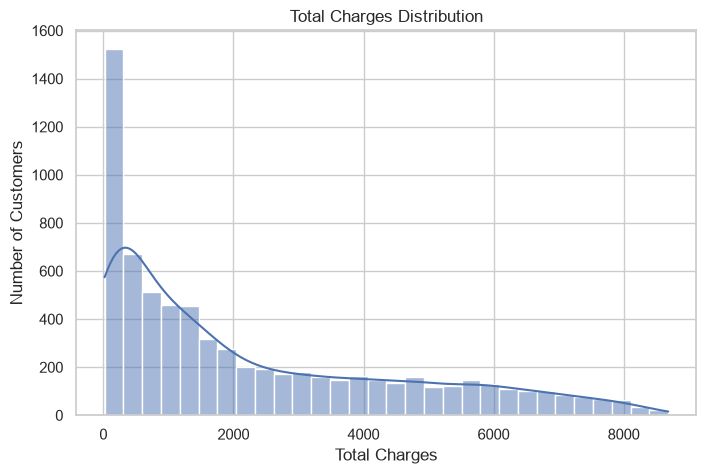

In [53]:
# Analyze total charges

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print(df['TotalCharges'].describe())

plt.figure(figsize=(8, 5))

sns.histplot(df['TotalCharges'].dropna(), bins=30, kde=True)

plt.title('Total Charges Distribution')
plt.xlabel('Total Charges')
plt.ylabel('Number of Customers')

plt.show()

Churn             No   Yes
Contract                  
Month-to-month  2220  1655
One year        1307   166
Two year        1647    48


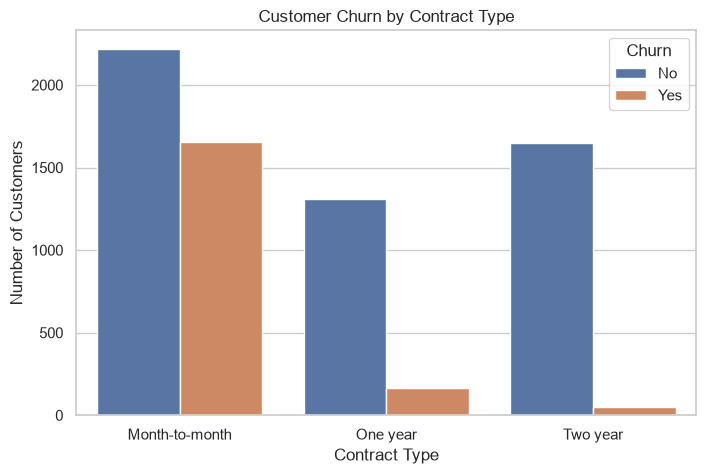

In [54]:
# Analyze churn by contract type

print(pd.crosstab(df['Contract'], df['Churn']))

plt.figure(figsize=(8, 5))

sns.countplot(x='Contract', hue='Churn', data=df)

plt.title('Customer Churn by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Number of Customers')

plt.show()

Churn              No   Yes
InternetService            
DSL              1962   459
Fiber optic      1799  1297
No               1413   113


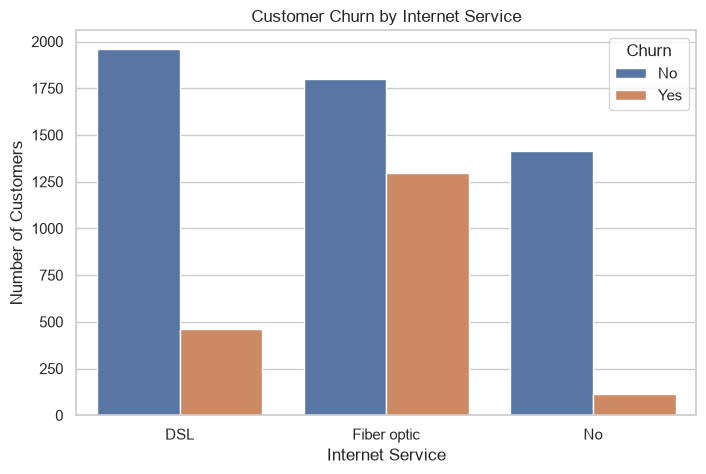

In [55]:
# Analyze churn by internet service

print(pd.crosstab(df['InternetService'], df['Churn']))

plt.figure(figsize=(8, 5))

sns.countplot(x='InternetService', hue='Churn', data=df)

plt.title('Customer Churn by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Number of Customers')

plt.show()

Churn                        No   Yes
PaymentMethod                        
Bank transfer (automatic)  1286   258
Credit card (automatic)    1290   232
Electronic check           1294  1071
Mailed check               1304   308


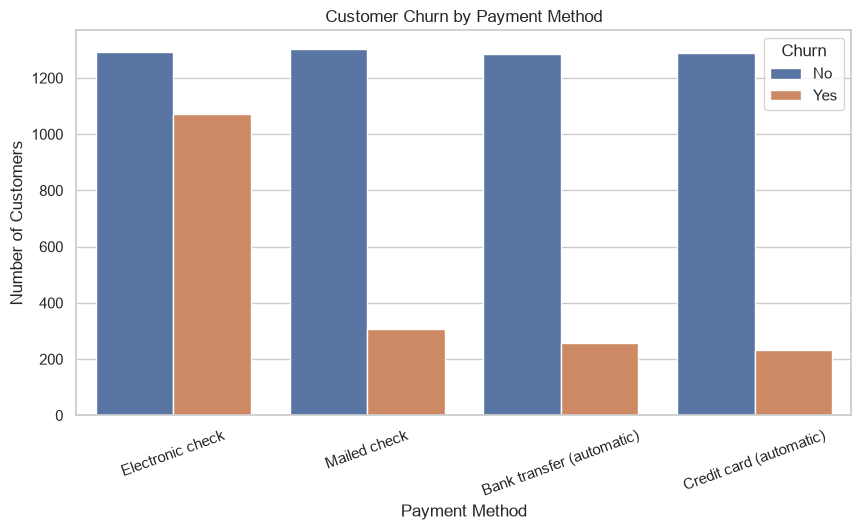

In [56]:
# Analyze churn by payment method

print(pd.crosstab(df['PaymentMethod'], df['Churn']))

plt.figure(figsize=(10, 5))

sns.countplot(x='PaymentMethod', hue='Churn', data=df)

plt.title('Customer Churn by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)

plt.show()

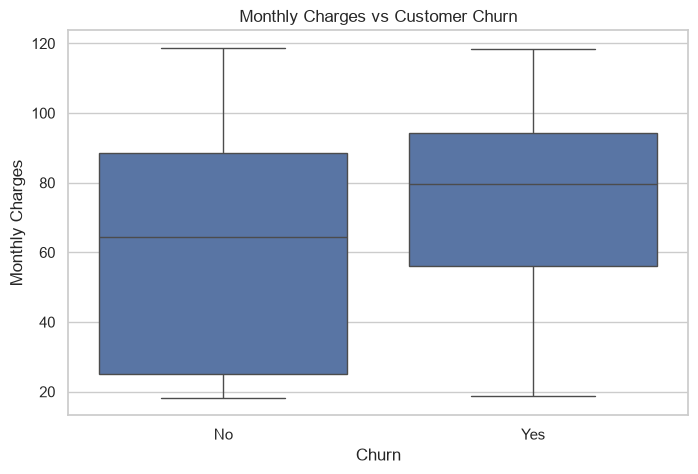

In [57]:
# Analyze churn by monthly charges

plt.figure(figsize=(8, 5))

sns.boxplot(x='Churn', y='MonthlyCharges', data=df)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn')
plt.ylabel('Monthly Charges')

plt.show()

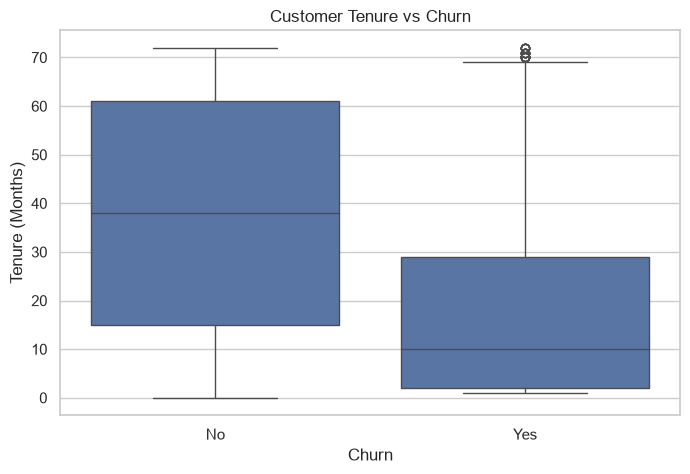

In [58]:
# Analyze churn by customer tenure

plt.figure(figsize=(8, 5))

sns.boxplot(x='Churn', y='tenure', data=df)

plt.title('Customer Tenure vs Churn')
plt.xlabel('Churn')
plt.ylabel('Tenure (Months)')

plt.show()

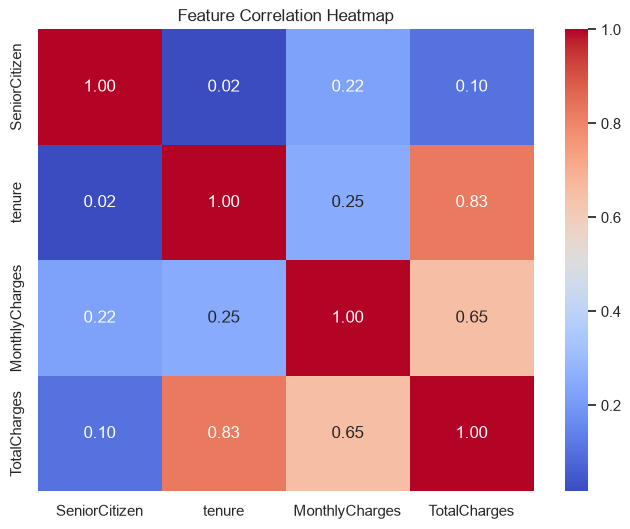

In [59]:
# Correlation heatmap

numeric_df = df.select_dtypes(include=['number'])

plt.figure(figsize=(8, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Feature Correlation Heatmap')
plt.show()

Churn     No  Yes
gender           
Female  2549  939
Male    2625  930


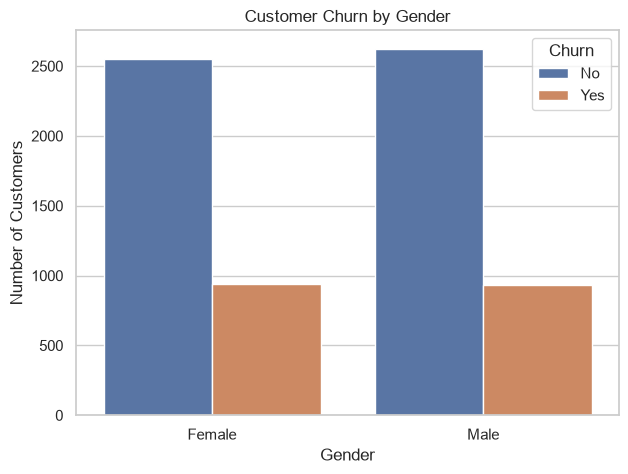

In [60]:
# Analyze churn by gender

print(pd.crosstab(df['gender'], df['Churn']))

plt.figure(figsize=(7, 5))

sns.countplot(x='gender', hue='Churn', data=df)

plt.title('Customer Churn by Gender')
plt.xlabel('Gender')
plt.ylabel('Number of Customers')

plt.show()

Churn            No   Yes
SeniorCitizen            
0              4508  1393
1               666   476


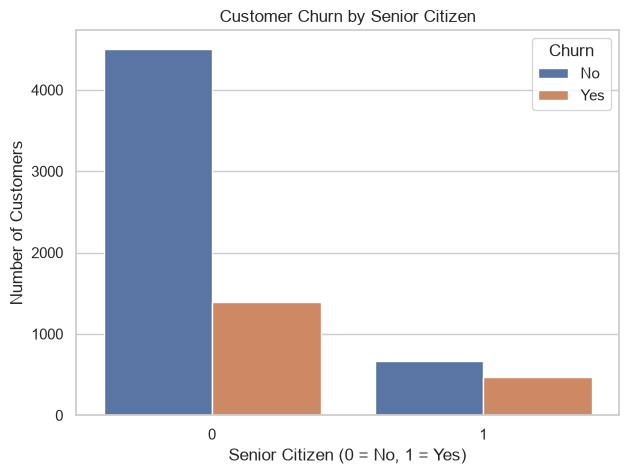

In [61]:
# Analyze churn by senior citizens

print(pd.crosstab(df['SeniorCitizen'], df['Churn']))

plt.figure(figsize=(7, 5))

sns.countplot(x='SeniorCitizen', hue='Churn', data=df)

plt.title('Customer Churn by Senior Citizen')
plt.xlabel('Senior Citizen (0 = No, 1 = Yes)')
plt.ylabel('Number of Customers')

plt.show()

Churn                  No   Yes
OnlineSecurity                 
No                   2037  1461
No internet service  1413   113
Yes                  1724   295


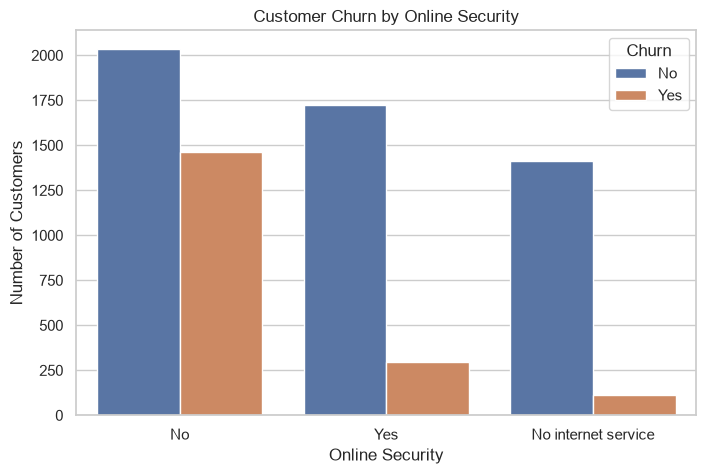

In [62]:
# Analyze churn by online security

print(pd.crosstab(df['OnlineSecurity'], df['Churn']))

plt.figure(figsize=(8, 5))

sns.countplot(x='OnlineSecurity', hue='Churn', data=df)

plt.title('Customer Churn by Online Security')
plt.xlabel('Online Security')
plt.ylabel('Number of Customers')

plt.show()

Churn                  No   Yes
TechSupport                    
No                   2027  1446
No internet service  1413   113
Yes                  1734   310


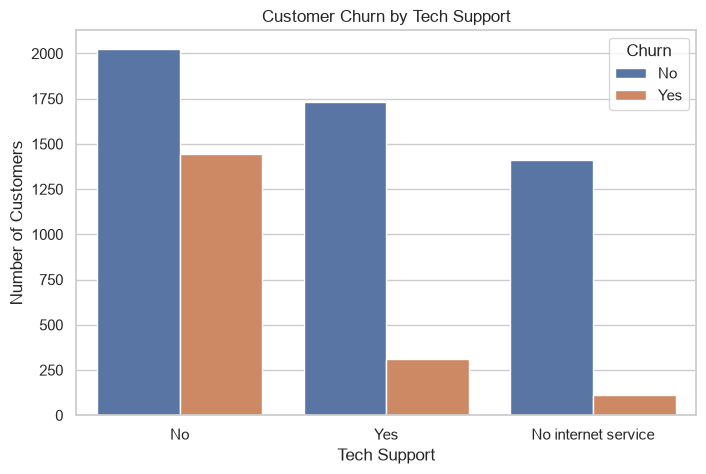

In [63]:
# Analyze churn by tech support

print(pd.crosstab(df['TechSupport'], df['Churn']))

plt.figure(figsize=(8, 5))

sns.countplot(x='TechSupport', hue='Churn', data=df)

plt.title('Customer Churn by Tech Support')
plt.xlabel('Tech Support')
plt.ylabel('Number of Customers')

plt.show()

In [64]:
# Calculate churn percentage by payment method

payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

print(payment_churn)

Churn                             No        Yes
PaymentMethod                                  
Bank transfer (automatic)  83.290155  16.709845
Credit card (automatic)    84.756899  15.243101
Electronic check           54.714588  45.285412
Mailed check               80.893300  19.106700


In [65]:
# Calculate churn percentage by contract type

contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

print(contract_churn)

Churn                  No        Yes
Contract                            
Month-to-month  57.290323  42.709677
One year        88.730482  11.269518
Two year        97.168142   2.831858


In [66]:
# Calculate churn percentage by internet service

internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


In [67]:
# Calculate churn percentage by gender

gender_churn = pd.crosstab(
    df['gender'],
    df['Churn'],
    normalize='index'
) * 100

print(gender_churn)

Churn          No        Yes
gender                      
Female  73.079128  26.920872
Male    73.839662  26.160338


In [68]:
# Calculate churn percentage by senior citizens

senior_churn = pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
) * 100

print(senior_churn)

Churn                 No        Yes
SeniorCitizen                      
0              76.393832  23.606168
1              58.318739  41.681261


In [69]:
# Calculate churn percentage by internet service

internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

print(internet_churn)

Churn                   No        Yes
InternetService                      
DSL              81.040892  18.959108
Fiber optic      58.107235  41.892765
No               92.595020   7.404980


In [70]:
# Import required libraries

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [71]:
# Calculate churn percentage by online security

security_churn = pd.crosstab(
    df['OnlineSecurity'],
    df['Churn'],
    normalize='index'
) * 100

print(security_churn)

Churn                       No        Yes
OnlineSecurity                           
No                   58.233276  41.766724
No internet service  92.595020   7.404980
Yes                  85.388806  14.611194


In [72]:
# Calculate churn percentage by tech support

tech_churn = pd.crosstab(
    df['TechSupport'],
    df['Churn'],
    normalize='index'
) * 100

print(tech_churn)

Churn                       No        Yes
TechSupport                              
No                   58.364526  41.635474
No internet service  92.595020   7.404980
Yes                  84.833659  15.166341


In [73]:
# Calculate churn percentage by partner status

partner_churn = pd.crosstab(
    df['Partner'],
    df['Churn'],
    normalize='index'
) * 100

print(partner_churn)

Churn           No        Yes
Partner                      
No       67.042021  32.957979
Yes      80.335097  19.664903


In [74]:
# Calculate churn percentage by dependents

dependents_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print(dependents_churn)

Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237


In [75]:
# Calculate churn percentage by phone service

phone_churn = pd.crosstab(
    df['PhoneService'],
    df['Churn'],
    normalize='index'
) * 100

print(phone_churn)

Churn                No        Yes
PhoneService                      
No            75.073314  24.926686
Yes           73.290363  26.709637


In [76]:
# Calculate churn percentage by dependents

dependents_churn = pd.crosstab(
    df['Dependents'],
    df['Churn'],
    normalize='index'
) * 100

print(dependents_churn)

Churn              No        Yes
Dependents                      
No          68.720860  31.279140
Yes         84.549763  15.450237


In [77]:
# Calculate churn percentage by multiple lines

multiple_lines_churn = pd.crosstab(
    df['MultipleLines'],
    df['Churn'],
    normalize='index'
) * 100

print(multiple_lines_churn)

Churn                    No        Yes
MultipleLines                         
No                74.955752  25.044248
No phone service  75.073314  24.926686
Yes               71.390104  28.609896


In [78]:
# Calculate churn percentage by online backup

backup_churn = pd.crosstab(
    df['OnlineBackup'],
    df['Churn'],
    normalize='index'
) * 100

print(backup_churn)

Churn                       No        Yes
OnlineBackup                             
No                   60.071244  39.928756
No internet service  92.595020   7.404980
Yes                  78.468506  21.531494


In [79]:
# Calculate churn percentage by device protection

device_churn = pd.crosstab(
    df['DeviceProtection'],
    df['Churn'],
    normalize='index'
) * 100

print(device_churn)

Churn                       No        Yes
DeviceProtection                         
No                   60.872375  39.127625
No internet service  92.595020   7.404980
Yes                  77.497936  22.502064


In [80]:
# Calculate churn percentage by streaming TV

streaming_tv_churn = pd.crosstab(
    df['StreamingTV'],
    df['Churn'],
    normalize='index'
) * 100

print(streaming_tv_churn)

Churn                       No        Yes
StreamingTV                              
No                   66.476868  33.523132
No internet service  92.595020   7.404980
Yes                  69.929812  30.070188


In [81]:
# Calculate churn percentage by streaming movies

streaming_movies_churn = pd.crosstab(
    df['StreamingMovies'],
    df['Churn'],
    normalize='index'
) * 100

print(streaming_movies_churn)

Churn                       No        Yes
StreamingMovies                          
No                   66.319569  33.680431
No internet service  92.595020   7.404980
Yes                  70.058565  29.941435


In [82]:
# Calculate churn percentage by paperless billing

billing_churn = pd.crosstab(
    df['PaperlessBilling'],
    df['Churn'],
    normalize='index'
) * 100

print(billing_churn)

Churn                    No        Yes
PaperlessBilling                      
No                83.669916  16.330084
Yes               66.434908  33.565092


In [83]:
# Compare average monthly charges by churn status

monthly_churn = df.groupby('Churn')['MonthlyCharges'].mean()

print(monthly_churn)

Churn
No     61.265124
Yes    74.441332
Name: MonthlyCharges, dtype: float64


In [84]:
# Compare average customer tenure by churn status

tenure_churn = df.groupby('Churn')['tenure'].mean()

print(tenure_churn)

Churn
No     37.569965
Yes    17.979133
Name: tenure, dtype: float64


In [85]:
# Compare average total charges by churn status

total_charges_churn = df.groupby('Churn')['TotalCharges'].mean()

print(total_charges_churn)

Churn
No     2555.344141
Yes    1531.796094
Name: TotalCharges, dtype: float64


In [86]:
# Convert TotalCharges to numeric format

df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

print(df['TotalCharges'].dtype)

float64


# Final Exploratory Data Analysis (EDA) Summary

1. The dataset contains 7043 customer records.
2. Overall customer churn rate is 26.54%.
3. Month-to-month contract customers have the highest churn rate.
4. Senior citizens have a higher churn rate than non-senior customers.
5. Fiber optic customers show higher churn.
6. Customers without online security are more likely to leave.
7. Customers without partners have a higher churn rate.
8. Customers who left have lower average total charges.
9. Longer contract periods are associated with better customer retention.

## Conclusion

Exploratory Data Analysis helped identify important factors associated with customer churn. Contract type, tenure, internet service, online security, and customer characteristics are useful features for further analysis and churn prediction.

## Assumptions

1. Customer information represents historical customer behavior.
2. The Churn column is the target variable.
3. CustomerID is an identifier and is not useful for prediction.
4. Missing TotalCharges values are treated as missing data.
5. The dataset contains an imbalanced target variable.

## Evaluation Metric

F1-score is selected as the primary evaluation metric because the dataset is imbalanced.

F1-score balances Precision and Recall. It helps identify customers who may leave while reducing false predictions.